# My small Vision Transformer trained from scratch

I add a small Vision Transformer (ViT) as an extra image-model experiment. I initialize every weight randomly and train using my BD3 training images. **I do not use pretrained weights.** This is a compact adaptation of ViT, not the full ViT-Base architecture.

I split a 96 × 96 image into 64 non-overlapping 12 × 12 patches. Each patch becomes a vector of 96 numbers. I add a learned class token and learned position vectors, pass the tokens through three standard transformer encoder blocks (four attention heads each), and classify the class token into seven labels. Each encoder block has a feed-forward width of 192 and dropout of 0.1. `vit_model.py` contains the shared model and image preparation used by the website.

This notebook is separate from the required five-fold classical-model comparison. I reuse the fixed 2,725 training / 584 validation / 584 test split. I choose the checkpoint using validation macro F1. The same test split has already been evaluated for earlier models; it is not a newly collected independent test set.

Run this notebook from the project folder after installing `requirements.txt`. The dataset can stay at its original location, or be placed beside this notebook. The included outputs come from actual execution of these cells.

In [1]:
from pathlib import Path
import csv, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms.functional import rotate
from PIL import Image
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from vit_model import build_model, prepare_image

torch.set_num_threads(4)
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
ROOT = Path.cwd()
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
RESULTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
DATASET = ROOT / "BD3_original_dataset"
if not DATASET.exists():
    DATASET = Path("/Users/daryn/Desktop/daat/BD3_original_dataset")
data = pd.read_csv(RESULTS / "split_manifest.csv").sort_values("path").reset_index(drop=True)
classes = sorted(data.label.unique())
print(pd.crosstab(data.label, data.split))
print("Dataset:", DATASET)

split        test  train  validation
label                               
algae          92    433          93
major_crack    86    403          87
minor_crack    87    404          86
peeling        78    360          77
plain          89    412          88
spalling       75    350          75
stain          77    363          78
Dataset: /Users/daryn/Desktop/daat/BD3_original_dataset


## 1. Prepare training and validation images

I apply EXIF orientation, put any transparency on white, resize to 96 × 96 with bilinear interpolation, and normalize RGB channels using mean 0.5 and standard deviation 0.5. I cache these small images in memory to avoid decoding the same files every epoch. I do not load the test images during training.

Only training batches receive random horizontal flips and rotations of up to 10 degrees. I apply augmentation before normalization; validation, test, and uploaded images use the same deterministic `prepare_image` function.

In [2]:
loaders = {}
for split in ["train", "validation"]:
    subset = data[data.split == split]
    images = []
    for path in subset.path:
        with Image.open(DATASET / path) as image:
            images.append(prepare_image(image))
    X = torch.stack(images)
    y = torch.tensor([classes.index(label) for label in subset.label])
    loaders[split] = DataLoader(TensorDataset(X, y), batch_size=32, shuffle=(split == "train"))
print("Cached training and validation images. Test images have not been loaded.")

Cached training and validation images. Test images have not been loaded.


## 2. Initialize and train my model

I use AdamW with learning rate 0.001 and weight decay 0.01, cross-entropy loss, and a cosine learning-rate schedule over a planned 50 epochs. Gradient clipping limits unusually large updates. Every encoder layer receives its own random initialization after construction; no weights come from a pretrained model.

I keep the checkpoint with the highest validation macro F1. I do not evaluate the test set while choosing epochs or training settings.

In [3]:
model = build_model()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50, eta_min=0.00001)
loss_function = nn.CrossEntropyLoss()
history = []
best_f1 = -1
print("Randomly initialized parameters:", sum(p.numel() for p in model.parameters()))
print("Encoder layers have different attention weights:",
      not torch.equal(model.encoder.layers[0].self_attn.in_proj_weight,
                      model.encoder.layers[1].self_attn.in_proj_weight))

for epoch in range(1, 51):
    start = time.perf_counter()
    model.train()
    train_loss = 0
    train_correct = 0
    for batch, labels in loaders["train"]:
        batch = (batch + 1) / 2
        flip = torch.rand(len(batch)) < 0.5
        batch[flip] = batch[flip].flip(-1)
        batch = rotate(batch, float(torch.empty(1).uniform_(-10, 10)))
        batch = (batch - 0.5) / 0.5
        optimizer.zero_grad()
        output = model(batch)
        loss = loss_function(output, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_loss += loss.item() * len(batch)
        train_correct += (output.argmax(1) == labels).sum().item()
    model.eval()
    predictions, true_labels = [], []
    validation_loss = 0
    with torch.inference_mode():
        for batch, labels in loaders["validation"]:
            output = model(batch)
            validation_loss += loss_function(output, labels).item() * len(batch)
            predictions.extend(output.argmax(1).tolist())
            true_labels.extend(labels.tolist())
    row = {"epoch": epoch, "learning_rate": optimizer.param_groups[0]["lr"],
           "train_loss": train_loss / len(loaders["train"].dataset),
           "train_accuracy": train_correct / len(loaders["train"].dataset),
           "validation_loss": validation_loss / len(loaders["validation"].dataset),
           "validation_accuracy": accuracy_score(true_labels, predictions),
           "validation_macro_f1": f1_score(true_labels, predictions, average="macro", zero_division=0),
           "seconds": round(time.perf_counter() - start, 2)}
    history.append(row)
    if row["validation_macro_f1"] > best_f1:
        best_f1 = row["validation_macro_f1"]
        torch.save(model.state_dict(), MODELS / "vit.pt")
        (RESULTS / "vit_best_validation.json").write_text(json.dumps(row, indent=2))
    pd.DataFrame(history).to_csv(RESULTS / "vit_history.csv", index=False)
    scheduler.step()
    print(f"Epoch {epoch:2d}/50 | train {row['train_accuracy']:.1%} | validation {row['validation_accuracy']:.1%} | macro F1 {row['validation_macro_f1']:.4f} | {row['seconds']:.1f}s", flush=True)
print("Training finished. The best validation checkpoint is frozen before testing.")

Randomly initialized parameters: 273127
Encoder layers have different attention weights: True
Epoch  1/50 | train 26.9% | validation 36.6% | macro F1 0.3330 | 3.9s
Epoch  2/50 | train 39.8% | validation 41.4% | macro F1 0.3787 | 3.7s
Epoch  3/50 | train 45.1% | validation 45.2% | macro F1 0.4119 | 3.8s
Epoch  4/50 | train 48.3% | validation 40.6% | macro F1 0.3952 | 3.8s
Epoch  5/50 | train 49.6% | validation 50.3% | macro F1 0.5023 | 3.8s
Epoch  6/50 | train 54.2% | validation 53.8% | macro F1 0.5326 | 3.8s
Epoch  7/50 | train 57.1% | validation 49.7% | macro F1 0.4482 | 3.9s
Epoch  8/50 | train 57.0% | validation 55.1% | macro F1 0.5300 | 3.8s
Epoch  9/50 | train 58.3% | validation 57.7% | macro F1 0.5544 | 3.8s
Epoch 10/50 | train 60.5% | validation 53.1% | macro F1 0.5173 | 3.7s
Epoch 11/50 | train 61.2% | validation 56.8% | macro F1 0.5576 | 3.7s
Epoch 12/50 | train 60.8% | validation 58.2% | macro F1 0.5611 | 3.7s
Epoch 13/50 | train 63.4% | validation 60.4% | macro F1 0.5883 | 3

## 3. Inspect the training curves

I use the recorded history to show the learning progress. The saved checkpoint can be earlier than the last epoch because I select it using validation macro F1.

Selected epoch: 40 | validation accuracy: 0.6935


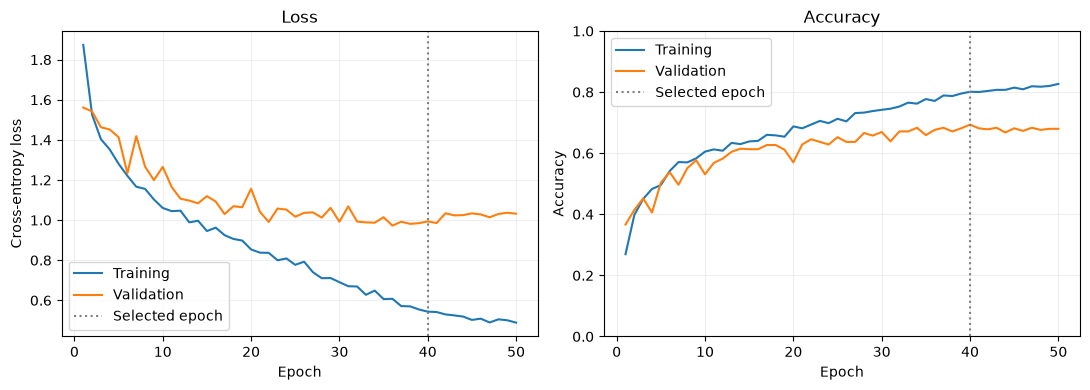

In [4]:
history = pd.read_csv(RESULTS / "vit_history.csv")
best = json.loads((RESULTS / "vit_best_validation.json").read_text())
print("Selected epoch:", best["epoch"], "| validation accuracy:", round(best["validation_accuracy"], 4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.epoch, history.train_loss, label="Training")
axes[0].plot(history.epoch, history.validation_loss, label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
axes[1].plot(history.epoch, history.train_accuracy, label="Training")
axes[1].plot(history.epoch, history.validation_accuracy, label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy", ylim=(0, 1))
for ax in axes:
    ax.axvline(best["epoch"], color="gray", linestyle=":", label="Selected epoch")
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS / "vit_training_curves.png", dpi=170)
plt.show()

## 4. Evaluate the frozen checkpoint once

Only now do I load the 584 test images. I use the saved checkpoint and deterministic image preparation. I report the measured result, even if it is lower than my CNN or classical models; I do not change training settings after seeing it. Prediction time measures the model forward pass and excludes image loading.

Test accuracy: 71.06% (415 / 584)
Test macro F1: 0.7055
              precision    recall  f1-score   support

       algae     0.8958    0.9348    0.9149        92
 major_crack     0.5833    0.6512    0.6154        86
 minor_crack     0.5357    0.5172    0.5263        87
     peeling     0.7385    0.6154    0.6713        78
       plain     0.8636    0.8539    0.8588        89
    spalling     0.7531    0.8133    0.7821        75
       stain     0.5811    0.5584    0.5695        77

    accuracy                         0.7106       584
   macro avg     0.7073    0.7063    0.7055       584
weighted avg     0.7104    0.7106    0.7092       584



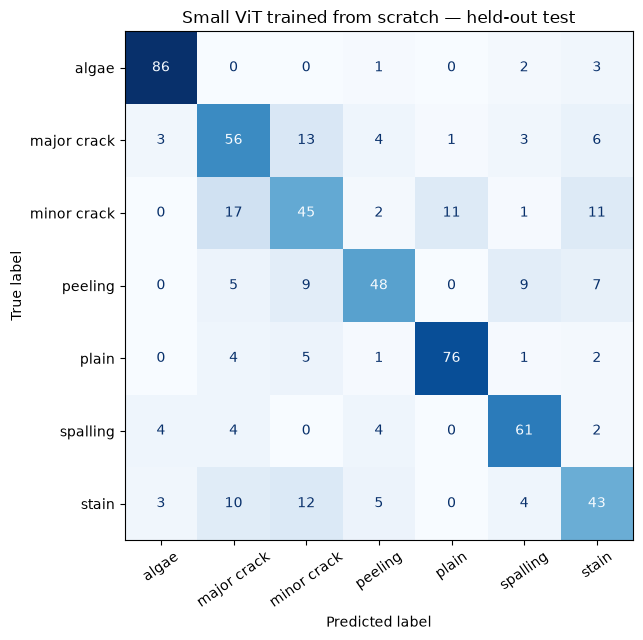

In [5]:
test_data = data[data.split == "test"]
images = []
for path in test_data.path:
    with Image.open(DATASET / path) as image:
        images.append(prepare_image(image))
X_test = torch.stack(images)
y_test = np.array([classes.index(label) for label in test_data.label])
model.load_state_dict(torch.load(MODELS / "vit.pt", map_location="cpu", weights_only=True))
model.eval()
start = time.perf_counter()
scores = []
with torch.inference_mode():
    for batch in X_test.split(32):
        scores.append(model(batch).softmax(1).numpy())
predict_seconds = time.perf_counter() - start
probabilities = np.concatenate(scores)
prediction = probabilities.argmax(1)
matrix = confusion_matrix(y_test, prediction, labels=range(7))
report = classification_report(y_test, prediction, labels=range(7), target_names=classes, output_dict=True, zero_division=0)
metrics = {"model": "Vision Transformer trained from scratch", "pretrained": False,
    "parameter_count": sum(p.numel() for p in model.parameters()), "epochs_planned": 50,
    "best_epoch": best["epoch"], "classes": classes, "validation_accuracy": best["validation_accuracy"],
    "validation_macro_f1": best["validation_macro_f1"], "checkpoint_selection": "highest validation macro F1 across 50 planned epochs",
    "split_counts": {"train": 2725, "validation": 584, "test": len(y_test)},
    "test_accuracy": accuracy_score(y_test, prediction), "test_precision_macro": precision_score(y_test, prediction, average="macro", zero_division=0),
    "test_recall_macro": recall_score(y_test, prediction, average="macro", zero_division=0),
    "test_macro_f1": f1_score(y_test, prediction, average="macro", zero_division=0),
    "test_balanced_accuracy": balanced_accuracy_score(y_test, prediction),
    "correct_count": int((prediction == y_test).sum()), "fit_seconds": float(history.seconds.sum()),
    "predict_seconds": predict_seconds, "classification_report": report, "confusion_matrix": matrix.tolist(),
    "timing_note": "Epoch time includes training and validation; prediction excludes image loading/preprocessing.",
    "architecture": {"image_size": 96, "patch_size": 12, "image_tokens": 64, "class_tokens": 1,
        "embedding_dimension": 96, "encoder_blocks": 3, "attention_heads": 4, "feedforward_dimension": 192, "dropout": 0.1},
    "training_settings": {"optimizer": "AdamW", "learning_rate": 0.001, "weight_decay": 0.01,
        "scheduler": "cosine decay, minimum lr 0.00001", "loss": "CrossEntropyLoss", "batch_size": 32,
        "seed": 42, "gradient_clip_norm": 1.0, "augmentation": "training-only horizontal flip and random rotation ±10 degrees",
        "preprocessing": "EXIF orientation, white alpha composite, RGB resize96x96 bilinear, normalize mean0.5 std0.5"},
    "test_reuse_note": "This fixed split was evaluated for earlier models. It did not select this ViT's settings or checkpoint."}
(RESULTS / "vit_metrics.json").write_text(json.dumps(metrics, indent=2))
np.save(RESULTS / "vit_test_probabilities.npy", probabilities)
test_results = test_data[["path", "label"]].copy().rename(columns={"label": "true_label"})
test_results["predicted_label"] = [classes[index] for index in prediction]
for index, label in enumerate(classes):
    test_results["prob_" + label] = probabilities[:, index]
test_results.to_csv(RESULTS / "vit_test_predictions.csv", index=False)
print(f"Test accuracy: {metrics['test_accuracy']:.2%} ({metrics['correct_count']} / {len(y_test)})")
print(f"Test macro F1: {metrics['test_macro_f1']:.4f}")
print(classification_report(y_test, prediction, target_names=classes, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(8, 6.5))
ConfusionMatrixDisplay(matrix, display_labels=[label.replace("_", " ") for label in classes]).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35)
ax.set_title("Small ViT trained from scratch — held-out test")
plt.tight_layout()
plt.savefig(RESULTS / "vit_confusion_matrix.png", dpi=180)
plt.show()

## My conclusion

I trained a genuine patch-based Vision Transformer with randomly initialized weights. Its measured results above show what this small model learned from the available dataset. I compare these scores honestly with my CNN and classical baselines rather than assuming the newer architecture must win.

The test split is image-level because no building identifiers were supplied. Similar scenes may remain across splits, and the model assigns one of seven labels even to unfamiliar images. This extra ViT experiment uses a validation checkpoint; it does not replace or claim the five-fold cross-validation performed for the classical models.

Reference: Dosovitskiy et al., [An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929). My compact architecture uses smaller images and patches and is trained entirely on this project dataset.

## How my image becomes patches

I show one training image split into an 8 × 8 grid. Each square becomes one input token; the learned class token is added separately.

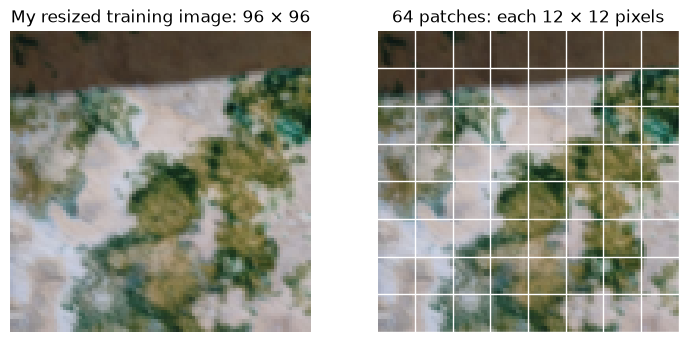

In [6]:
example = data[data.split == "train"].iloc[0]
with Image.open(DATASET / example.path) as image:
    rgb = ((prepare_image(image) + 1) / 2).permute(1, 2, 0).numpy()
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.5))
for ax in axes:
    ax.imshow(rgb)
    ax.set_xlim(-0.5, 95.5)
    ax.set_ylim(95.5, -0.5)
    ax.axis("off")
axes[0].set_title("My resized training image: 96 × 96")
axes[1].set_title("64 patches: each 12 × 12 pixels")
for edge in np.arange(11.5, 96, 12):
    axes[1].axvline(edge, color="white", linewidth=1)
    axes[1].axhline(edge, color="white", linewidth=1)
plt.tight_layout()
plt.savefig(RESULTS / "vit_patch_example.png", dpi=170)
plt.show()

## Update my website

I save the selected weights to `models/vit.pt`. This final cell updates only the ViT registry entry and comparison row; other trained models stay available. Rerunning training can change these results, so my report should be updated if I retrain.

In [7]:
name = "ViT trained from scratch"
metrics = json.loads((RESULTS / "vit_metrics.json").read_text())
registry_path = ROOT / "models/registry.json"
registry = json.loads(registry_path.read_text()) if registry_path.exists() else {}
registry[name] = {"type": "vit", "file": "models/vit.pt", "test_accuracy": metrics["test_accuracy"], "classes": metrics["classes"]}
registry_path.write_text(json.dumps(registry, indent=2))

row = {"Model": name, "Accuracy": metrics["test_accuracy"], "Precision macro": metrics["test_precision_macro"],
       "Recall macro": metrics["test_recall_macro"], "F1 macro": metrics["test_macro_f1"],
       "Balanced accuracy": metrics["test_balanced_accuracy"], "Development accuracy": np.nan,
       "Fit seconds": metrics["fit_seconds"], "Predict seconds": metrics["predict_seconds"]}
comparison_path = RESULTS / "model_comparison.csv"
comparison = pd.read_csv(comparison_path) if comparison_path.exists() else pd.DataFrame(columns=row)
comparison = comparison[comparison.Model != name]
comparison = pd.concat([comparison, pd.DataFrame([row])], ignore_index=True) if not comparison.empty else pd.DataFrame([row])
comparison.to_csv(comparison_path, index=False)
print("Updated only the ViT website entry and comparison row.")

Updated only the ViT website entry and comparison row.
